# Decision Trees

**Agenda**

1. Where decision trees fit
2. What is a decision tree
3. Choosing the best question: entropy and information gain
4. The ID3 algorithm
5. Numerical features
6. Overfitting and pruning
7. Decision trees in practice - forests and boosting
8. Comparison with other algorithms
9. Pros and cons
10. Summary
11. Homework: ID3 on the breast cancer dataset

## Setup: imports and helper code

The helpers draw the figures. `grow_threshold_tree` is a version of the tree algorithm from section 4 for numerical
features (section 5). You do not need to understand the helper code.

In [1]:
# The imports used in the rest of the notebook
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Helper code that can be skipped

def draw_entropy_curve():
    p = np.linspace(0.001, 0.999, 400)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(p, -p * np.log2(p) - (1 - p) * np.log2(1 - p), color="#1f4e79", lw=2)
    for share, name in ((0.0, "S1: all one class"), (0.75, "S2: 75% / 25%"), (0.5, "S3: 50% / 50%")):
        h = 0.0 if share == 0 else -share * np.log2(share) - (1 - share) * np.log2(1 - share)
        ax.plot(share, h, "o", color="#c62828", markersize=9)
        ax.annotate(f"{name}\nH = {h:.3f}", (share, h), xytext=(8, -28 if share == 0.5 else 8),
                    textcoords="offset points", fontsize=9)
    ax.set_xlabel("p = the fraction of examples in the positive class")
    ax.set_ylabel("entropy H (bits)")
    ax.set_title("Entropy of a set with two classes")
    plt.close(fig)
    return fig


def draw_gains(gains):
    fig, ax = plt.subplots(figsize=(8, 3))
    names = sorted(gains, key=gains.get)
    ax.barh(names, [gains[n] for n in names], color=["#c62828" if n == names[-1] else "#4f81bd" for n in names])
    for i, n in enumerate(names):
        ax.text(gains[n] + 0.003, i, f"{gains[n]:.3f}", va="center")
    ax.set_xlabel("information gain (bits)")
    ax.set_title("Which question to ask first? The one with the highest gain")
    plt.close(fig)
    return fig


def draw_tree(tree, feature_names=None, title="", ax=None):
    # a tree is a class label (a leaf) or {"feature": i (or "question": text), "children": {value: subtree}, ...}
    positions, edges, labels = {}, [], {}
    next_leaf = [0]

    def place(node, depth, key):
        if not isinstance(node, dict):
            positions[key] = (next_leaf[0], -depth)
            labels[key] = (str(node), True)
            next_leaf[0] += 1
            return
        for value, child in node["children"].items():
            child_key = key + (value,)
            place(child, depth + 1, child_key)
            edges.append((key, child_key, value))
        xs = [positions[key + (value,)][0] for value in node["children"]]
        positions[key] = (sum(xs) / len(xs), -depth)
        question = node["question"] if "question" in node else feature_names[node["feature"]]
        labels[key] = (question + "?", False)

    place(tree, 0, ())
    if ax is None:
        depth = -min(y for _, y in positions.values())
        _, ax = plt.subplots(figsize=(1.7 * next_leaf[0] + 2, 1.6 * (1 + depth) + 0.5))
    leaf_colours = {"Yes": "#a5d6a7", "No": "#ef9a9a", "0": "#ef9a9a", "1": "#90caf9"}
    for parent, child, value in edges:
        (x1, y1), (x2, y2) = positions[parent], positions[child]
        ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, value, ha="center", va="center", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none"})
    for key, (x, y) in positions.items():
        text, is_leaf = labels[key]
        colour = leaf_colours.get(text, "#e3f2fd") if is_leaf else "#fff3c4"
        ax.text(x, y, text, ha="center", va="center", fontsize=11, fontweight="bold",
                bbox={"boxstyle": "round,pad=0.5", "facecolor": colour, "edgecolor": "black"})
    ax.set_xlim(-0.8, next_leaf[0] - 0.2)
    ax.set_ylim(min(y for _, y in positions.values()) - 0.5, 0.5)
    ax.axis("off")
    ax.set_title(title)
    plt.close(ax.figure)
    return ax.figure


def draw_split(examples):
    # examples: (the value of feature A, the class) for every example of S; an example keeps its number in its child
    values = sorted(set(value for value, _ in examples))
    branch_colour = dict(zip(values, ["#4f81bd", "#f79646", "#8064a2", "#9bbb59", "#4bacc6"]))
    class_colour = {"Yes": "#a5d6a7", "No": "#ef9a9a"}
    total, root_y, child_y = len(examples), 5.2, 0.0
    fig, ax = plt.subplots(figsize=(11, 6.4))

    def draw_examples(xs, y, numbers):
        ax.scatter(xs, [y] * len(xs), s=330, c=[class_colour[examples[k][1]] for k in numbers], edgecolors="black",
                   zorder=3)
        for x, k in zip(xs, numbers):
            ax.text(x, y, str(k + 1), ha="center", va="center", fontsize=8, zorder=4)

    def describe(labels):
        return f"{labels.count('Yes')}Y/{labels.count('No')}N"

    labels = [label for _, label in examples]
    root_entropy = binary_entropy(labels.count("Yes") / total)
    ax.add_patch(plt.Rectangle((-0.6, root_y - 0.85), total + 0.2, 1.4, facecolor="#fff3c4", edgecolor="black"))
    draw_examples(np.arange(total), root_y, range(total))
    for k, (value, _) in enumerate(examples):
        ax.text(k, root_y - 0.55, value, ha="center", va="center", fontsize=8, fontweight="bold",
                color=branch_colour[value])
    ax.text((total - 1) / 2, root_y - 1.0, r"$S$", ha="center", va="top", fontsize=16)
    ax.text((total - 1) / 2, root_y - 1.6, f"{describe(labels)}\n" + rf"$H(S) = {root_entropy:.3f}$", ha="center",
            va="top", fontsize=10, linespacing=1.6)

    terms, after = [], 0.0
    start = -(len(values) - 1) * 0.75
    for value in values:
        numbers = [k for k, (v, _) in enumerate(examples) if v == value]
        subset = [examples[k][1] for k in numbers]
        subset_entropy = binary_entropy(subset.count("Yes") / len(subset))
        after += len(subset) / total * subset_entropy
        terms.append(rf"\frac{{{len(subset)}}}{{{total}}} \cdot {subset_entropy:.3f}")
        xs = start + np.arange(len(subset))
        start += len(subset) + 1.5
        colour = branch_colour[value]
        ax.add_patch(plt.Rectangle((xs[0] - 0.6, child_y - 0.55), len(subset) + 0.2, 1.1, facecolor="#f7f7f7",
                                   edgecolor=colour, lw=2.5))
        draw_examples(xs, child_y, numbers)
        ax.plot([(total - 1) / 2, xs.mean()], [root_y - 2.7, child_y + 0.55], color=colour, lw=2, zorder=1)
        ax.text(((total - 1) / 2 + xs.mean()) / 2, (root_y - 2.7 + child_y + 0.55) / 2, f"A = {value}",
                ha="center", va="center", fontsize=10, fontweight="bold", color=colour,
                bbox={"facecolor": "white", "edgecolor": colour, "boxstyle": "round,pad=0.3"})
        ax.text(xs.mean(), child_y - 0.7, rf"$S_{{{value}}}$", ha="center", va="top", fontsize=16)
        ax.text(xs.mean(), child_y - 1.3, f"{describe(subset)}\n" + rf"$|S_{{{value}}}|\,/\,|S| = "
                rf"{len(subset)}/{total}$" + "\n" + rf"$H(S_{{{value}}}) = {subset_entropy:.3f}$",
                ha="center", va="top", fontsize=10, linespacing=1.6)

    ax.text((total - 1) / 2, -3.6, rf"$\mathrm{{Gain}}(S, A) = H(S) - \sum_v \frac{{|S_v|}}{{|S|}} H(S_v) = "
            rf"{root_entropy:.3f} - ({' + '.join(terms)}) = {root_entropy - after:.3f}$",
            ha="center", va="center", fontsize=14)
    for name, colour in class_colour.items():
        ax.scatter([], [], s=120, c=colour, edgecolors="black", label=name)
    ax.legend(loc="upper right", frameon=False, title="class")
    margin = (len(values) - 1) * 0.75 + 1
    ax.set_xlim(-margin, total - 1 + margin)
    ax.set_ylim(-4.1, root_y + 0.8)
    ax.axis("off")
    ax.set_title("Splitting S on feature A")
    plt.close(fig)
    return fig


def make_two_groups(n, rng, spread=1.3):
    # two overlapping clouds of points in 2D, labelled 0 and 1
    X = np.vstack([rng.normal([2.0, 2.0], spread, (n, 2)), rng.normal([4.5, 4.0], spread, (n, 2))])
    return X, np.r_[np.zeros(n, int), np.ones(n, int)]


def binary_entropy(p):
    return 0.0 if p in (0, 1) else -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


def grow_threshold_tree(X, y, max_depth=None, depth=0):
    # like ID3, but every question is "feature j <= threshold t?"; a leaf is the majority class (0 or 1)
    if len(set(y)) == 1 or (max_depth is not None and depth >= max_depth):
        return int(y.mean() > 0.5)
    best = None
    for j in range(X.shape[1]):
        order = np.argsort(X[:, j])
        xs, ys = X[order, j], y[order]
        ones_left = np.cumsum(ys)
        for k in range(1, len(ys)):                       # try every threshold between two neighbouring values
            if xs[k] == xs[k - 1]:
                continue
            left = binary_entropy(ones_left[k - 1] / k)
            right = binary_entropy((ones_left[-1] - ones_left[k - 1]) / (len(ys) - k))
            gain = binary_entropy(ys.mean()) - (k * left + (len(ys) - k) * right) / len(ys)
            if best is None or gain > best[0]:
                best = (gain, j, (xs[k] + xs[k - 1]) / 2)
    if best is None:
        return int(y.mean() > 0.5)
    _, j, t = best
    goes_left = X[:, j] <= t
    return (j, t, grow_threshold_tree(X[goes_left], y[goes_left], max_depth, depth + 1),
            grow_threshold_tree(X[~goes_left], y[~goes_left], max_depth, depth + 1))


def predict_threshold_tree(tree, X):
    predictions = []
    for x in X:
        node = tree
        while isinstance(node, tuple):
            j, t, left, right = node
            node = left if x[j] <= t else right
        predictions.append(node)
    return np.array(predictions)


def threshold_tree_to_dict(tree):
    if not isinstance(tree, tuple):
        return tree
    j, t, left, right = tree
    return {"question": f"x{j + 1} ≤ {t:.1f}",
            "children": {"yes": threshold_tree_to_dict(left), "no": threshold_tree_to_dict(right)}}


def draw_regions(X_train, y_train, X_val, y_val, depths):
    fig, axes = plt.subplots(2, len(depths), figsize=(5 * len(depths), 8), height_ratios=[4.2, 3.8])
    x1, x2 = np.meshgrid(np.linspace(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5, 300),
                         np.linspace(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5, 300))
    for ax, tree_ax, max_depth in zip(axes[0], axes[1], depths):
        tree = grow_threshold_tree(X_train, y_train, max_depth)
        regions = predict_threshold_tree(tree, np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
        ax.contourf(x1, x2, regions, levels=[-0.5, 0.5, 1.5], colors=["#ef9a9a", "#90caf9"], alpha=0.6)
        ax.scatter(*X_train[y_train == 0].T, c="#c62828", s=18, edgecolors="white", linewidths=0.5)
        ax.scatter(*X_train[y_train == 1].T, c="#1f4e79", s=18, marker="s", edgecolors="white", linewidths=0.5)
        train_accuracy = np.mean(predict_threshold_tree(tree, X_train) == y_train)
        val_accuracy = np.mean(predict_threshold_tree(tree, X_val) == y_val)
        name = "no limit" if max_depth is None else f"max depth {max_depth}"
        ax.set_title(f"{name}\ntrain accuracy {train_accuracy:.0%}, validation {val_accuracy:.0%}")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        if max_depth is None:
            tree_ax.text(0.5, 0.5, "the tree is too big to draw", ha="center", va="center", fontsize=12)
            tree_ax.axis("off")
        else:
            draw_tree(threshold_tree_to_dict(tree), ax=tree_ax)
    fig.tight_layout()
    plt.close(fig)
    return fig


def draw_depth_curve(X_train, y_train, X_val, y_val, depths):
    train_accuracy, val_accuracy = [], []
    for max_depth in depths:
        tree = grow_threshold_tree(X_train, y_train, max_depth)
        train_accuracy.append(np.mean(predict_threshold_tree(tree, X_train) == y_train))
        val_accuracy.append(np.mean(predict_threshold_tree(tree, X_val) == y_val))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(depths, train_accuracy, "o-", color="#4f81bd", label="training accuracy")
    ax.plot(depths, val_accuracy, "o-", color="#f79646", label="validation accuracy")
    best = depths[int(np.argmax(val_accuracy))]
    ax.axvline(best, color="gray", linestyle="--")
    ax.text(best, min(train_accuracy), f" best depth = {best}", va="bottom")
    ax.set_xlabel("maximum depth of the tree (model complexity)")
    ax.set_ylabel("accuracy")
    ax.legend(loc="lower right")
    plt.close(fig)
    return fig

---

# 1. Where decision trees fit

A **decision tree** is:

- **supervised learning** - it learns from labelled examples
- used for **classification** and for **regression**
- **nonparametric** - the size and structure of the tree is not fixed in advance

We all use decision trees without calling them that. A doctor asks: "Do you have a fever? If yes - is there a cough?
If yes - ...". Every question splits the possibilities, until the answer is clear. A decision tree **learns which
questions to ask, and in which order**, from the training data.

---

# 2. What is a decision tree

- Each **internal node** tests one feature of the example ("What is the Outlook?").
- Each **branch** leaving a node corresponds to one possible value (or a range of values) of the tested feature
  ("Sunny", "Overcast", "Rain").
- Each **leaf** gives the prediction, which is a class label in classification, or a number in regression.

To classify an example, start at the root, follow the branch that matches the example's value for the tested feature,
and repeat until a leaf is reached. The leaf's label is the prediction.

Below is a tree for the tennis data from the last lecture ("do we play tennis today?"). It is exactly the tree that the
ID3 algorithm (section 4) learns from this data:

In [3]:
feature_names = ("Outlook", "Temperature", "Humidity", "Wind")
tennis_days = [
    ("Sunny", "Hot", "High", "Weak", "No"), ("Sunny", "Hot", "High", "Strong", "No"),
    ("Overcast", "Hot", "High", "Weak", "Yes"), ("Rain", "Mild", "High", "Weak", "Yes"),
    ("Rain", "Cool", "Normal", "Weak", "Yes"), ("Rain", "Cool", "Normal", "Strong", "No"),
    ("Overcast", "Cool", "Normal", "Strong", "Yes"), ("Sunny", "Mild", "High", "Weak", "No"),
    ("Sunny", "Cool", "Normal", "Weak", "Yes"), ("Rain", "Mild", "Normal", "Weak", "Yes"),
    ("Sunny", "Mild", "Normal", "Strong", "Yes"), ("Overcast", "Mild", "High", "Strong", "Yes"),
    ("Overcast", "Hot", "Normal", "Weak", "Yes"), ("Rain", "Mild", "High", "Strong", "No"),
]
tennis_X = [day[:4] for day in tennis_days]          # the features
tennis_y = [day[4] for day in tennis_days]           # the class

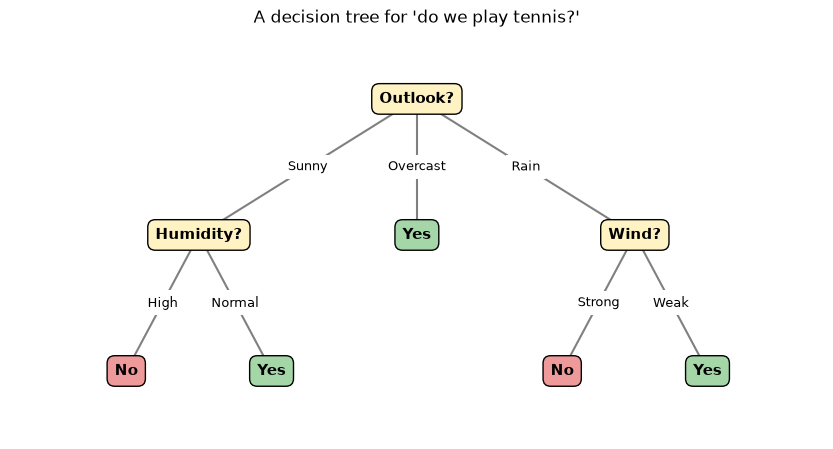

In [4]:
# written by hand: a node asks about a feature (0 = Outlook, 2 = Humidity, 3 = Wind), a string is a leaf
_example_tree = {"feature": 0, "children": {
    "Sunny": {"feature": 2, "children": {"High": "No", "Normal": "Yes"}},
    "Overcast": "Yes",
    "Rain": {"feature": 3, "children": {"Strong": "No", "Weak": "Yes"}},
}}
draw_tree(_example_tree, feature_names, title="A decision tree for 'do we play tennis?'")

A new day (Sunny, Cool, High, Strong):
- Outlook = Sunny → follow the "Sunny" branch
- Humidity = High → **No**

A tree can also be read as a set of **if-then rules**, every path from the root to a leaf is a conjunction (AND) of
tests, and the whole tree is the disjunction (OR) of the paths. The paths that end in "Yes" give:

$$(\text{Outlook} = \text{Sunny} \land \text{Humidity} = \text{Normal}) \;\lor\; (\text{Outlook} = \text{Overcast}) \;\lor\; (\text{Outlook} = \text{Rain} \land \text{Wind} = \text{Weak})$$

So we can think of a tree as a **disjunction of conjunctions, which is Disjunctive Normal Form (DNF)**.

Trees are easy to explain to anyone because you just follow the path and see **why** the model decided what it decided.

---

# 3. Choosing the best question

The tree is built from the top down, one question at a time. A natural question that arises when we try to build the tree is **which feature should we test first?** A
good question splits the examples into groups that are each as **pure** as possible. Ideally, each group contains only
one class. We need a number that measures how "mixed" a group is. For this, we will use the **entropy**.

## 3.1 Entropy

Let $S$ be a set of examples with two classes, and $p$ and $q$ the fractions of positive and negative examples
($p + q = 1$). The **entropy** of $S$ is:

$$H(S) = -p \log_2 p - q \log_2 q = -p \log_2 p - (1-p) \log_2 (1-p)$$

> By convention $0 \log_2 0 = 0$.

Entropy is measured in **bits**, which can be interpreted as how many yes/no questions we need on average to learn the class of a random example from $S$.

- $H(S) = 0$ bits when $S$ is **pure**. All examples are in one class, there is no uncertainty, and we need no questions.
- $H(S) = 1$ bit when $S$ is **maximally mixed**. Half of the examples are in one class and the other half are in the second class.

The tennis data has 9 "Yes" and 5 "No" days:

$$H(S) = -\frac{9}{14} \log_2 \frac{9}{14} - \frac{5}{14} \log_2 \frac{5}{14} \approx 0.940 \text{ bits}$$

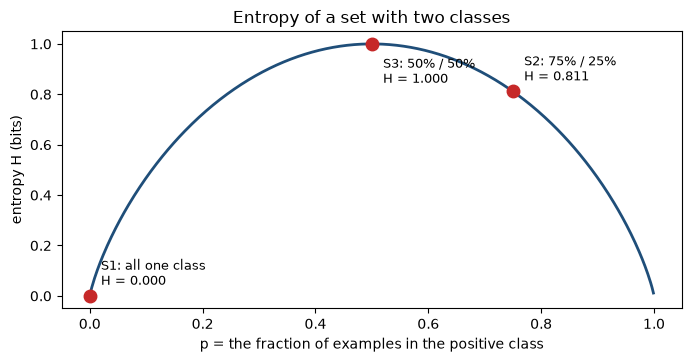

In [5]:
draw_entropy_curve()

With $K$ classes the formula is the same sum over all classes:

$$H(S) = -\sum_{k=1}^{K} p_k \log_2 p_k$$

and the maximum is $\log_2 K$ bits, when all classes are equally common. E.g. a fair die (6 equally likely outcomes) has entropy
$\log_2 6 \approx 2.585$ bits.

## 3.2 Information gain

**Information gain** measures how much splitting the set $S$ on a feature $A$ **reduces the entropy**. Basically, it is used to measure **which question will separate the classes better**. This is the same as having lower entropy overall. The formula for Information Gain is:

$$\text{Gain}(S, A) = \underbrace{H(S)}_{\text{before the split}} - \underbrace{\sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} \, H(S_v)}_{\text{after the split (weighted average)}}$$

- $S_v$ is the subset of examples where $A$ has the value $v$
- $H(S)$ is the entropy of the set before the split
- $H(S_v)$ is the entropy of the subset $S_v$ (after the split)
- $H(S_v)$ is weighted by $\frac{|S_v|}{|S|}$, the share of the examples in $S_v$ - a big messy subset hurts more than a
  small one

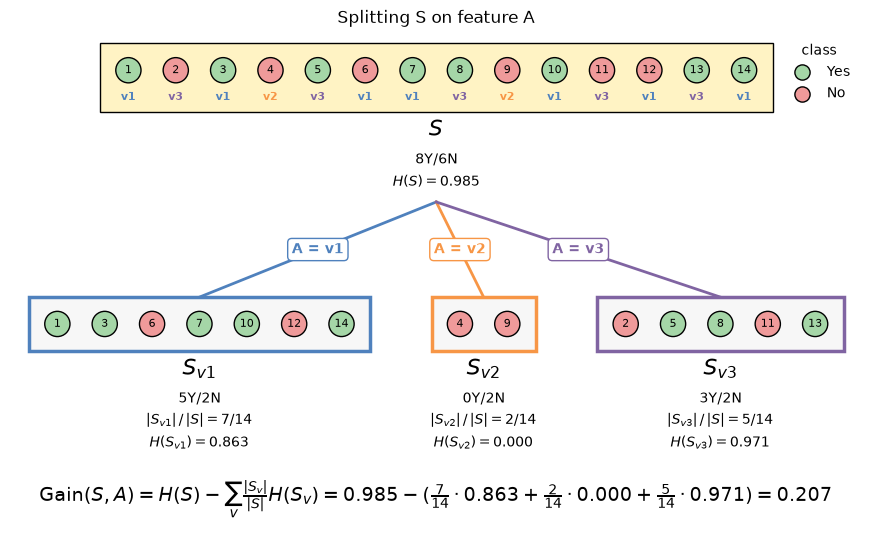

In [6]:
# every example of S as (its value of the feature A, its class)
draw_split([("v1", "Yes"), ("v3", "No"), ("v1", "Yes"), ("v2", "No"), ("v3", "Yes"), ("v1", "No"), ("v1", "Yes"),
            ("v3", "Yes"), ("v2", "No"), ("v1", "Yes"), ("v3", "No"), ("v1", "No"), ("v3", "Yes"), ("v1", "Yes")])

## 3.3 Implementation

In [7]:
def entropy(labels):
    # Calculates H(S)
    counts = Counter(labels) # creates a dict with label counts, e.g. {"Yes": 9, "No": 5}
    total_sum = 0

    for count in counts.values():
        p = count / len(labels)
        total_sum -= p * np.log2(p)

    return total_sum


def information_gain(X, y, i):
    # Calculates Gain(S, A_i)
    after = 0.0

    for v in set(x[i] for x in X):
        subset = [label for x, label in zip(X, y) if x[i] == v]   # the labels of the examples with x_i = v
        after += len(subset) / len(y) * entropy(subset)

    return entropy(y) - after

For the tennis data:

entropy of all 14 days: 0.940


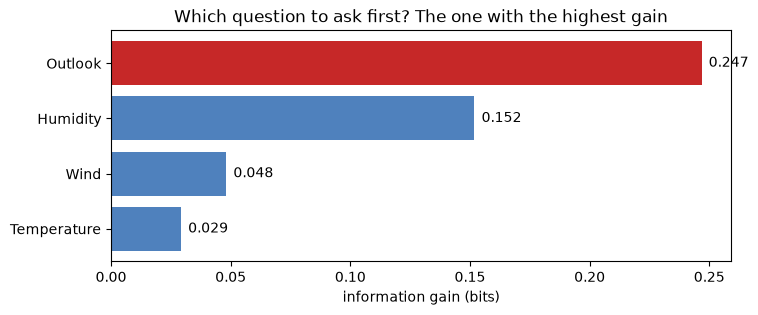

In [8]:
print(f"entropy of all 14 days: {entropy(tennis_y):.3f}")
draw_gains({name: information_gain(tennis_X, tennis_y, i) for i, name in enumerate(feature_names)})

---

# 4. The ID3 algorithm

**ID3 (Iterative Dichotomiser 3)** builds the tree **greedily from the top down**. It starts with one root node that
contains all the training examples, and repeats for every node:

1. If all examples of the node are in the same class (the node is **pure**), or there are no features left to test,
   make the node a **leaf** with the **majority class** of its examples. Stop.
2. Otherwise, compute the information gain of every remaining feature, and pick the feature with the **highest** gain.
3. Create one child node for every value of that feature, and send every example to the child that matches its value.
4. Repeat from step 1 for every child, with its own examples and the **remaining** features.


"Greedy" means that at every node ID3 takes the question that looks best **right now**, and never goes back to reconsider
it, like **hill climbing**. It does not guarantee the smallest or the best possible tree, but it is fast and works well.

---

# 5. Numerical features

ID3 works with categorical features. With **numerical** features (height, price, temperature in °C) there are too many
values to make one branch per value. Instead, a node asks a **yes/no question with a threshold**: "is $x_j \le t$?" To
choose $t$, sort the examples by $x_j$, try every threshold between two neighbouring values, and keep the one with the
highest information gain.

Every such question cuts the feature space with a line **perpendicular to the axis** of feature $x_j$ (a vertical or a
horizontal line in 2D). Every next question cuts one of the resulting regions again. So the tree splits the feature
space into **rectangles**, one per leaf, and all points in a rectangle get the same prediction.

Below, we split two overlapping groups of points with trees of different maximum depths:

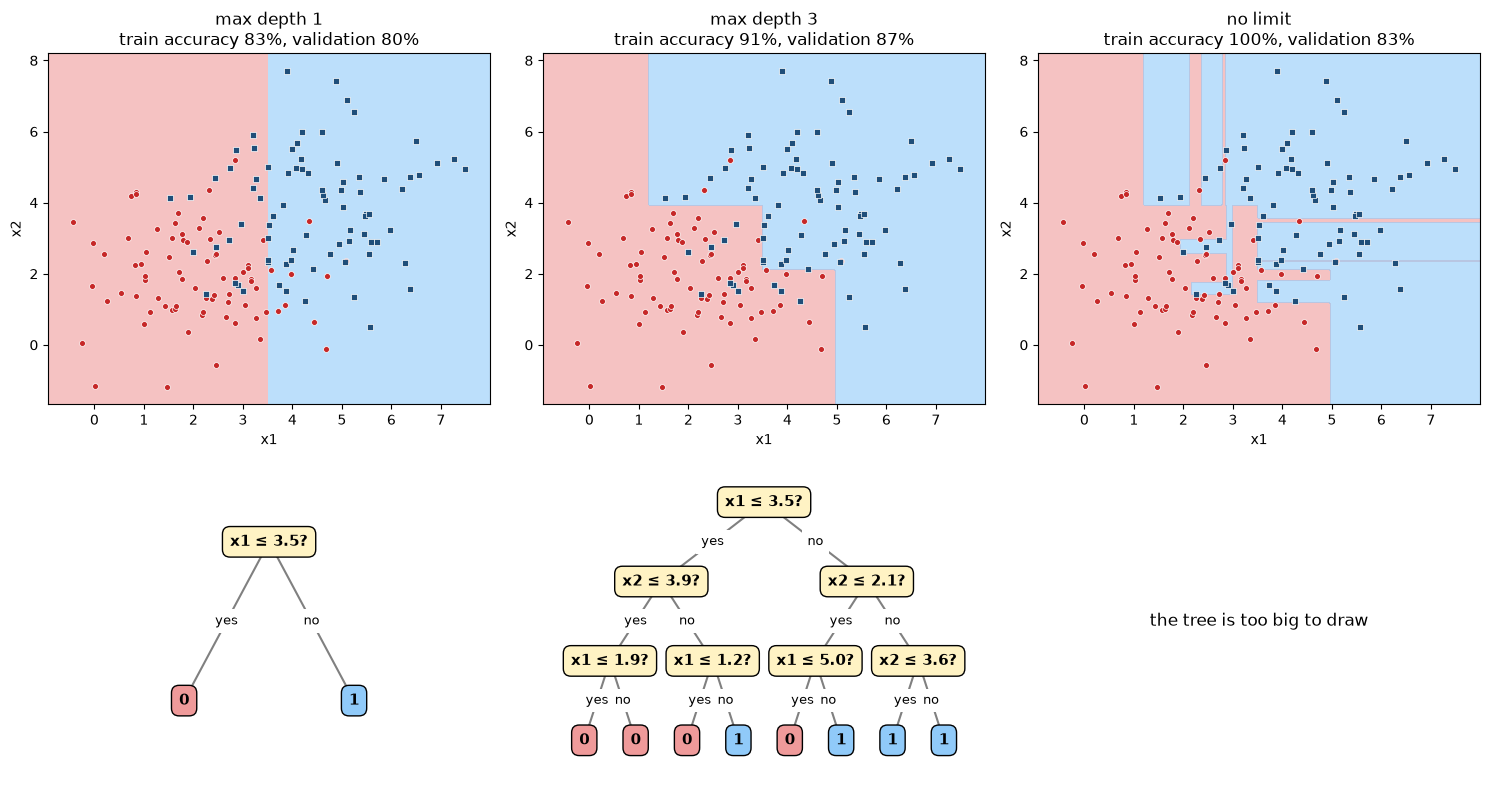

In [9]:
_rng = np.random.default_rng(2)
groups_X_train, groups_y_train = make_two_groups(80, _rng)
groups_X_val, groups_y_val = make_two_groups(400, _rng)
draw_regions(groups_X_train, groups_y_train, groups_X_val, groups_y_val, depths=(1, 3, None))

- **Max depth 1**: a single question - one vertical line. Simple, but crude (**underfitting**).
- **Max depth 3**: a few rectangles.
- **No limit**: the tree keeps asking questions until every leaf is pure, achieving 100% training accuracy. It carves out tiny rectangles around single points that are on the "wrong" side because of noise (**overfitting**). The validation accuracy is lower than with depth 3.

> The true boundary between the groups is a **diagonal** line, and decision trees can only
  approximate it with a **staircase** of horizontal and vertical steps. Logistic regression will probably perform better on this data, since it could draw this diagonal with a single line.
---

# 6. Overfitting and pruning

## 6.1 A deep tree memorizes

Without a limit, a tree grows until every leaf is pure. With enough questions it can always separate the training examples perfectly (unless two identical examples
have different labels), even if the leaves end up containing
one example each. Such a tree has learned the **noise** of the training set, not the pattern:

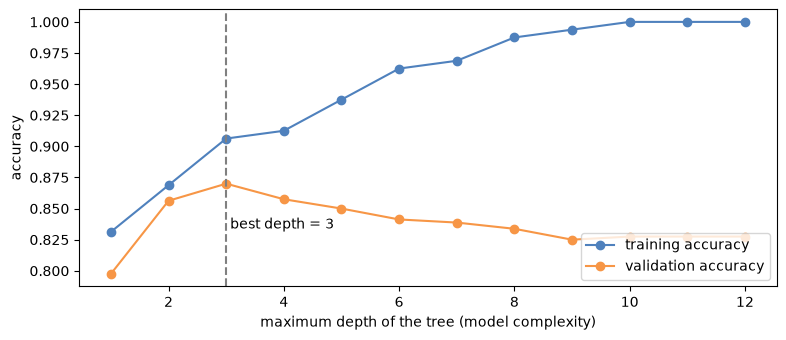

In [10]:
draw_depth_curve(groups_X_train, groups_y_train, groups_X_val, groups_y_val, depths=list(range(1, 13)))

The familiar picture from the previous lectures: the training accuracy keeps rising to 100%, the validation accuracy is
best for a shallow tree and then falls. The depth of the tree controls its complexity:

- a **shallow** tree: high bias, low variance - underfitting
- a **deep** tree: low bias, high variance - overfitting

## 6.2 Pruning

The general fixes for overfitting still apply: more training data, fewer features, cross-validation to choose the
hyperparameters. The technique specific to trees is **pruning** - keeping the tree small, so it does not fit the noise.

**Pre-pruning** - stop growing the tree early. A node becomes a leaf (predicting its majority class) when:

- the tree has reached a **maximum depth**
- the node has fewer than a **minimum number of examples** (too few to trust a further split)
- the best split has an information gain below a **minimum gain**

**Post-pruning** - first grow the full tree, then cut back the branches that do not help.
For example, **reduced error pruning** tries to replace a subtree with a leaf, and keeps the change if the accuracy on a **validation** set does not get worse, or discards it if it gets worse. Repeat while it helps.

> Pre-pruning is simpler and faster, but it can stop too early - a split that looks useless now may enable very useful splits below it. Post-pruning sees the whole tree before deciding, which usually gives better results. The thresholds (maximum depth, minimum examples, minimum gain) are **hyperparameters** - choose them with a validation set or with cross-validation.

---

# 7. Decision trees in practice - forests and boosting

A single tree is easy to read but unstable and prone to overfitting. In practice, trees are almost always used in
**ensembles** - many trees combined into one model.

A **random forest** trains hundreds of deep trees, each on a random sample of the training data (drawn with replacement - "bagging") and with only a random subset of the features available at each split, and lets them vote (or averages them for regression). The different trees make different mistakes, so averaging them mainly **reduces the variance**.

**Gradient boosting** (for example **XGBoost**, LightGBM and CatBoost) trains shallow trees **one after another**, each new tree learning to correct the errors of all the previous ones, which mainly **reduces the bias**.

> **IMPORTANT: Gradient-boosted trees are one of the strongest methods for tabular data (tables of features, like the datasets in this course), and they win many machine learning competitions. They are also widely used in practice for all kinds of different domains. Hypothetically if we could only use one algorithm for all tabular data, we should probably choose XGBoost (for images, audio and text, neural networks are much better).**

---

# 8. Comparison with other algorithms

| | Decision tree | Naive Bayes | kNN | Logistic regression |
|---|---|---|---|---|
| **Task** | classification and regression | classification | classification and regression | classification |
| **Parametric?** | no - the tree grows with the data | yes - a table of probabilities | no - stores all the data | yes - $n + 1$ weights |
| **Training** | greedy splitting - fast | counting - very fast | none | gradient descent |
| **Prediction** | very fast: a few questions | fast | slow: a distance to every point | fast |
| **Shape of the boundary** | axis-aligned rectangles (staircase) | depends on the features | any shape | a straight line |
| **Feature scaling** | not needed - only the order of the values matters | not needed | essential | helps |
| **Features that interact** (e.g. XOR) | yes - a question below another question | no | yes | no |
| **Irrelevant features** | mostly ignored - they rarely have the highest gain | add noise | hurt (curse of dimensionality) | weights near 0 |
| **Interpretable?** | very - readable if-then rules | yes - the probabilities | "these were the similar examples" | yes - the weights |
| **Main weakness** | overfitting, instability | the independence assumption | slow, needs scaling | only straight boundaries |

---

# 9. Pros and cons of decision trees

| Pros | Cons |
|---|---|
| easy to understand and explain - the tree is a set of if-then rules | overfits easily - needs pruning or a depth limit |
| very fast prediction - a few questions from the root to a leaf | unstable: a small change of the data can produce a very different tree |
| no feature scaling needed - only the order of the values matters | axis-aligned boundaries: a diagonal boundary needs a long staircase |
| handles categorical and numerical features | greedy: each split is chosen locally, the tree is not guaranteed to be the best one |
| learns interactions between features (a question below another question) | information gain favours features with many values (e.g. an ID feature splits the data into pure groups of one example) |
| mostly ignores irrelevant features - a useless feature is rarely chosen | a single tree is usually less accurate than other methods |
| works for classification and for regression | with imbalanced classes, the majority class tends to fill the leaves |
| the building block of random forests and gradient boosting - the strongest tabular methods | |

**When to use a single decision tree**: when the model must be **explained** (medicine, credit decisions, rules for
people to follow), as a quick first look at which features matter most (the ones near the root), and as the building
block of a forest or a boosted model.

---

# 10. Summary

| Concept | In one sentence |
|---|---|
| **Decision tree** | internal nodes ask questions about features, branches are the answers, leaves give the prediction |
| **Entropy** | how mixed the classes in a set are: 0 for a pure set, 1 bit for a 50 / 50 split of two classes |
| **Information gain** | the drop in (weighted) entropy after splitting on a feature - ID3 asks the question with the highest gain |
| **ID3** | greedy, top-down, recursive: split on the best feature, repeat for every child until the nodes are pure |
| **Numerical features** | questions with thresholds, "$x_j \le t$?" - the tree splits the space into rectangles |
| **Overfitting** | a deep tree memorizes the noise; the depth controls the complexity |
| **Pre-pruning / post-pruning** | stop growing early (depth, examples, gain) / grow fully, then cut back what does not help |
| **Random forest / boosting** | many trees voting (lower variance) / trees correcting each other (lower bias) |

---

# 11. Homework: ID3 Decision Tree for Breast Cancer Recurrence

## 11.1 Problem definition

Implement the **ID3 decision tree** classification algorithm and apply it to the `breast-cancer.arff` dataset:
[archive.ics.uci.edu/ml/datasets/breast+cancer](https://archive.ics.uci.edu/ml/datasets/breast+cancer).

- **Missing values**: some attributes contain the value `?`, which denotes a missing value. Fill them in with an
  approach of your choice, and **justify** why you chose it.
- **Pruning**: to prevent overfitting, use at least **one pre-pruning** and at least **one post-pruning** approach of your
  choice. Every additional pruning approach counts as a **bonus**.
    - Pre-pruning: **N** - a maximum depth of the tree; **K** - a minimum number of training examples in a node;
      **G** - a minimum information gain.
    - Post-pruning: **E** - error estimation (reduced error pruning); **X** - the χ² (chi-squared) test;
      **C** - minimal cost-complexity pruning.
- **Data splitting**: shuffle the data and split it into a training and a test set in an **80 : 20** ratio. The split
  must be **stratified**, so that the class proportions (201 no-recurrence, 85 recurrence) are preserved in the training
  set, the test set, and the validation sets of the cross-validation.
- **Input**: `0` - use only pre-pruning, `1` - only post-pruning, `2` - both. Specific variants can be selected with
  letters after the number: `0` means all implemented pre-pruning variants, `0 K` means only the minimum-examples variant.
  The same logic applies to all other combinations.
- **Output**:
    1. The **training set accuracy** - the model trained and evaluated on the training set.
    2. The **10-fold cross-validation** results on the training set: the accuracy of every fold, the **average
       accuracy**, and the **standard deviation**.
    3. The **test set accuracy**.

Example - input `0`, output (the numbers only show the format):

```
1. Train Set Accuracy:
    Accuracy: 70.90%

10-Fold Cross-Validation Results:

    Accuracy Fold 1: 71.00%
    Accuracy Fold 2: 69.72%
    ...
    Accuracy Fold 10: 71.09%

    Average Accuracy: 70.90%
    Standard Deviation: 1.37%

2. Test Set Accuracy:
    Accuracy: 69.07%
```

## 11.2 The data

**286 patients** after breast cancer surgery; the class says whether the cancer **came back** (`recurrence-events`, 85)
or not (`no-recurrence-events`, 201). **9 categorical attributes**, e.g. the age group (`40-49`), menopause status, the
tumour size range (`20-24`), the number of affected lymph nodes (`inv-nodes`), the degree of malignancy (1 - 3), the left
or right breast, whether the patient had radiation therapy. Missing values (`?`) appear only in `node-caps` (8 patients)
and `breast-quad` (1 patient).

## 11.3 Tactics to try

- **Missing values**: the most common value of the attribute (computed on the **training** data only), or the most
  common value **within the same class**, or `?` as one more value of the attribute. With only 9 missing values out of
  286 × 9, the choice matters little for the accuracy - but the justification is part of the task.
- **Values that appear as numbers** (`20-24`, `40-49`) are categories in this dataset - treat them as categorical values,
  ID3 needs no thresholds here.
- **Unseen values**: a node's training examples may not contain every value of the attribute (especially in the smaller
  cross-validation folds). When predicting, return the node's majority class.
- **Pre-pruning** is easy to add to ID3: one more stopping condition in step 1 (section 4), next to "pure or no features
  left".
- **Post-pruning**:
    - **E** (reduced error pruning) needs a separate **validation** set, taken from the training data.
    - **X**: a χ² test checks whether a split's class distribution differs **significantly** from what a random split
      would give; if not, the split is removed.
    - **C**: cost-complexity pruning penalizes the tree for every leaf, minimizing error + α · (number of leaves).
- **Expect a low accuracy**: this dataset is hard - always predicting "no-recurrence" already gives 201 / 286 ≈ 70%. Compare
  your accuracies with this baseline, and look at the confusion matrix (from the kNN lecture) to see whether the tree
  finds any recurrence cases at all.